# dmg777k: what is in the data, and how the GeoRDF2Vec repo reads it

Exploratory analysis for Milestone 2 of our GeoRDF2Vec project. It answers three questions:

1. **What does dmg777k contain?** (Sections 1, 3)
2. **What does this repository's code do to the data before learning from it, and what follows from that?** (Section 2)
3. **Does the data support our planned contributions:** adaptive walk length, locality-aware walks and relation-aware flooding? (Section 4)

**To run it:** `uv sync`, `uv run scripts/download_dmg777k.py`, `uv run python data_preparation/dmg_data_prep.py`, then run this notebook top to bottom. It takes about 2 minutes and about 3 GB of memory. Figures are exported to `reports/figures/`. Labels from the test split are only counted, never used to compare methods.

## Main outcomes

- **The graph is the paper's graph.** The repo's parsing gives 776,920 edges and an average degree of 4.6775, both exactly as in the paper. It gives 332,194 nodes, so the paper's 331,194 is probably a typo.
- **The code does things the paper does not describe.** Most importantly, walks follow edges in one direction and stop at the first literal, so they average about 1.7 steps out of 8. The paper never states a walk direction, so this comes from the code. As committed, the word2vec training call also processes no data. Section 2 lists every case with evidence.
- **The location signal is real but modest.** Class varies with place (Cramér's V = 0.30), yet coordinates alone do not beat always guessing the largest class on accuracy. Macro F1 does double compared with shuffled labels (0.259 vs 0.133).
- **Flooding gives many nodes a useless location.** The `Geometry` class is linked to almost every shape, so its inherited location is the middle of the country, and 18.5% of all nodes inherit that same point.
- **Some relations link nearby things, others don't.** Monuments sharing a postal code are typically 30 m from their group's average position, and those sharing a city 370 m. Those sharing a build year or house number are 66–73 km away, about as spread out as monuments in general (75 km). This tells us which relations relation-aware flooding should keep. Monuments already have their own coordinates, so the change can only affect the values around them, such as years and addresses. Whether that improves classification is not yet measured.

In [1]:
import sys
from itertools import chain

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shapely
from gensim.models.word2vec import Word2Vec
from igraph import Graph
from scipy.stats import chi2_contingency
from sklearn.metrics import accuracy_score, f1_score
from sklearn.neighbors import KNeighborsClassifier

from eda import plots, spatial as sp
from eda.dmg777k import data
from eda.graph import build_graph
from eda.paths import REPO_ROOT

sys.path.insert(0, str(REPO_ROOT))
from geo_rdf2vec import GeoRDF2Vec

plots.apply_style()
pd.set_option("display.max_colwidth", 70, "display.width", 160)

def short(iri: str) -> str:
    """Last part of an IRI, for readable labels."""
    return iri.rstrip("/").rsplit("/", 1)[-1].rsplit("#", 1)[-1]

raw_nodes = data.load_raw_nodes()
raw_triples = data.load_raw_triples()
relations = data.load_relations()
triples = data.load_prepared_triples()
graph = build_graph(triples)
names = graph.vs["name"]
vertex_of = {name: i for i, name in enumerate(names)}
labels = data.load_labels(raw_nodes)
print(f"{len(raw_nodes):,} raw nodes, {len(raw_triples):,} raw triples, {len(relations)} relations")
print(f"{graph.vcount():,} nodes and {graph.ecount():,} edges in the prepared graph")

341,270 raw nodes, 777,124 raw triples, 60 relations
332,194 nodes and 776,920 edges in the prepared graph


## 1. What the data is

dmg777k describes Dutch national monuments as a **knowledge graph**: a network of things and the facts linking them. It was published in the KGBench collection (Bloem et al., 2021). The task is **node classification**: predict which of 5 classes a monument belongs to. The files contain only class numbers, so we don't know the class names.

| Term | Meaning here |
|---|---|
| **Triple** | One fact: subject → predicate → object. For example, monument 10000 → `postal-code` → `4455 TK`. |
| **Node, edge** | Subjects and objects are nodes. Each triple is one edge. |
| **Predicate (relation)** | The type of a link, such as `city`. |
| **Entity (IRI)** | A thing with a web-address-style name, such as a monument or a photo. |
| **Literal** | A plain value, such as text, a number or a year. It can only be an object. |
| **WKT** | Well-Known Text, a text format for shapes: `POLYGON ((4.66 51.81, ...))`. |
| **WGS84, RD New** | Two coordinate systems: global degrees (GPS), and the Dutch national system in metres. |

These are all the facts about one monument (one example shown per relation):

In [2]:
example = "https://data.labs.pdok.nl/rce/id/monument/10000"
rows = triples[triples["subject"] == example].copy()
rows["predicate"] = rows["predicate"].map(short)
rows["object"] = rows["object"].str.slice(0, 62)
rows[["predicate", "object"]].groupby("predicate", as_index=False).first()

,predicate,object
0,city,http://sws.geonames.org/2750356/
1,codeNationalMonument,10000
2,depiction,https://data.labs.pdok.nl/rce/id/image/20164172
3,description,"Boerderij ""Landlust"". Gepleisterd woonhuis met pannen zadeldak"
4,hasGeometry,http://bag.basisregistraties.overheid.nl/bag/id/geometry/5C55B
5,hasStreetAddress,Landlustweg
6,huisnummer,1
7,huisnummerCompleet,1
8,postal-code,4455 TK
9,seeAlso,https://data.labs.pdok.nl/rce/id/monument/10000


**Reading this:** a monument has about a dozen kinds of fact. Its location is not stored on it directly. The path has two hops: monument → `hasGeometry` → geometry node → `asWKT` → WKT literal.

### What kinds of node exist?

KGBench gives every literal its own node, including whole images stored as text. The `annotation` column in `nodes.int.csv` tells them apart. Its value `none` means plain text with no datatype or language tag, not an empty value.

Triples whose subject is not an entity: 0


Repeated identical triples: 0
Node pairs joined by more than one relation: 56,002


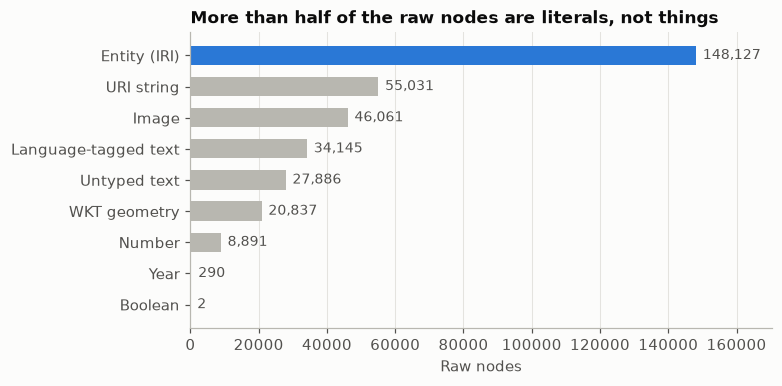

,nodes,share
kind,,
Entity (IRI),148127,43.4%
URI string,55031,16.1%
Image,46061,13.5%
Language-tagged text,34145,10.0%
Untyped text,27886,8.2%
WKT geometry,20837,6.1%
Number,8891,2.6%
Year,290,0.1%
Boolean,2,0.0%


In [3]:
raw_nodes["kind"] = raw_nodes["annotation"].map(data.annotation_group)
composition = raw_nodes["kind"].value_counts().rename("nodes").to_frame()
composition["share"] = (composition["nodes"] / len(raw_nodes)).map("{:.1%}".format)
datatypes = raw_nodes["annotation"].value_counts().rename("nodes").to_frame()

is_literal_subject = raw_nodes.set_index("index")["annotation"].reindex(raw_triples["s"]).ne("iri").sum()
print("Triples whose subject is not an entity:", is_literal_subject)
print("Repeated identical triples:", raw_triples.duplicated().sum())
pairs = raw_triples[["s", "o"]]
print("Node pairs joined by more than one relation:", f"{pairs.value_counts().gt(1).sum():,}")

ordered = composition["nodes"].sort_values()
fig, ax = plt.subplots(figsize=(7, 3.4))
colours = [plots.BLUE if kind == "Entity (IRI)" else plots.NEUTRAL for kind in ordered.index]
ax.barh(ordered.index, ordered.values, color=colours, height=0.62)
for y, value in enumerate(ordered.values):
    ax.text(value + 2000, y, f"{value:,}", va="center", color=plots.MUTED, fontsize=9)
ax.set(title="More than half of the raw nodes are literals, not things", xlabel="Raw nodes")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, ordered.max() * 1.15)
plots.save(fig, "node_composition")
plt.show()
composition

**Interpretation:** 56.6% of raw nodes are literals, and 13.5% are images. Every subject in the data is an entity, which confirms the reading of literals as end points of the graph. That matters in Section 2, because a walk cannot leave a literal. There are no repeated triples, but 56,002 pairs of nodes are joined by more than one relation, so this is a multigraph.

## 2. How the repo parses the data, and what follows

The pipeline has seven steps. Steps 1 and 2 run the repo's own logic. Steps 3 to 6 are re-implemented in `src/eda/spatial.py`, bugs included, because the repo runs them only as one long training job and does not expose values such as flooding rounds. They were checked for matching behaviour: flooding against the repo's function on small graphs, and walks against igraph. Step 7 was only tested on a toy corpus. So the results below describe what the repo's logic does, not what the paper describes, and this code is for analysis only, not a replacement for the training pipeline.

### Steps 1–2: from files to a graph

`data_preparation/dmg_data_prep.py` replaces integer IDs with node text, converts RD New geometries to WGS84, and calls `dropna()`. `geo_rdf2vec.py` then builds an igraph graph from the text, so **two nodes with the same text become one node**. The `annotation` column is dropped.

In [4]:
raw_counts = {"Nodes": len(raw_nodes), "Edges": len(raw_triples), "Average degree": 2 * len(raw_triples) / len(raw_nodes)}
prepared_counts = {"Nodes": graph.vcount(), "Edges": graph.ecount(), "Average degree": 2 * graph.ecount() / graph.vcount()}
paper_counts = {"Nodes": 331_194, "Edges": 776_920, "Average degree": 4.6775}
pd.DataFrame({"Raw files": raw_counts, "Repo pipeline": prepared_counts, "Paper (Sec. 5.2)": paper_counts}).round(4)

,Raw files,Repo pipeline,Paper (Sec. 5.2)
Nodes,341270.0000,332194.0000,331194.0000
Edges,777124.0000,776920.0000,776920.0000
Average degree,4.5543,4.6775,4.6775


In [5]:
sizes = raw_nodes.groupby("label").size()
shared_text = sizes[sizes > 1]
print(f"Texts shared by several nodes: {len(shared_text):,}, removing {(shared_text - 1).sum():,} nodes")
combos = (
    raw_nodes[raw_nodes["label"].isin(shared_text.index)]
    .groupby("label")["kind"]
    .agg(lambda kinds: " + ".join(sorted(set(kinds))))
    .value_counts()
)
print(combos.head(6).to_string())

empty = raw_nodes.loc[raw_nodes["label"] == "", "index"]
lost = raw_triples[raw_triples["o"].isin(empty)]
print(f"\nEmpty-text nodes: {len(empty)}; triples dropped with them: {len(lost)}")
print(lost["p"].map(relations).map(short).value_counts().to_string())

loops = np.array(graph.is_loop())
loop_predicates = pd.Series(graph.es["predicate"])[loops].map(short).value_counts()
print(f"\nSelf-loops after merging: {loops.sum():,}")
print(loop_predicates.to_string())
monument_iris = set(labels["node"])
loop_nodes = {names[graph.es[int(e)].source] for e in np.flatnonzero(loops)}
print("Labelled monuments with a self-loop:", f"{len(monument_iris & loop_nodes):,} of {len(monument_iris):,}")

Texts shared by several nodes: 9,028, removing 9,075 nodes
kind
Entity (IRI) + URI string              8396
Language-tagged text + Untyped text     266
Untyped text + Year                     247
Number                                   48
Number + Untyped text + Year             42
Number + Untyped text                    29

Empty-text nodes: 1; triples dropped with them: 204
p
creator      102
fotograaf    101
created        1

Self-loops after merging: 8,396
seeAlso    8396
Labelled monuments with a self-loop: 8,396 of 8,396


**Interpretation:**

- **These steps reproduce the paper's graph.** Edges and average degree match exactly. The paper's average degree only works with 332,194 nodes (2 × 776,920 / 332,194 = 4.6775), so its 331,194 is probably a typo.
- **The merging is undocumented, but we keep it for the baseline** so that our comparison uses the same graph as the paper. 9,075 nodes disappear, and 8,396 of those merges are monuments joining a `seeAlso` URI string with the same text.
- **Merging gives every labelled monument a self-loop,** because of that `seeAlso` edge.
- **One empty-text literal disappears,** along with 204 photo-credit and date triples. The effect should be negligible.

### Step 3: which nodes count as geographic

The repo marks a node as geographic if its text matches a regular expression for WKT. Note what this means: the starting points of flooding are the **WKT literals themselves**, not monuments.

In [6]:
repo_seeds = sp.find_wkt_nodes(names, sp.REPO_WKT_PATTERN)
fixed_seeds = sp.find_wkt_nodes(names, sp.ANY_CASE_WKT_PATTERN)
repo_geometries = sp.parse_geometries(sp.extract_wkt(names[i]) for i in repo_seeds)
fixed_geometries = sp.parse_geometries(sp.extract_wkt(names[i]) for i in fixed_seeds)

fixed_text = pd.Series([names[i] for i in fixed_seeds])
spelling = fixed_text.str.extract(r"^([A-Za-z]+)")[0].value_counts().rename("WKT literals").rename_axis("Spelling").to_frame()
spelling["Repo recognises it"] = [bool(sp.REPO_WKT_PATTERN.match(f"{word} (x)")) for word in spelling.index]
print(f"Recognised by the repo: {len(repo_seeds):,}   Actually in the graph: {len(fixed_seeds):,}")
spelling

Recognised by the repo: 12,851   Actually in the graph: 21,208


,WKT literals,Repo recognises it
Spelling,,
POLYGON,11215,True
Point,8357,False
POINT,1536,True
MULTIPOLYGON,100,True


**Interpretation:** the regular expression is case-sensitive, so it misses all **8,357 literals spelled `Point(...)`**, which is 39% of the geometries. Section 4 measures the effect: monument locations do not change, but thousands of edge lengths do.

### Step 4: flooding

Each round, nodes without a location inherit the geometries of the nearest located nodes. Edges are followed in both directions.

In [7]:
repo_flood = sp.flood(graph, repo_seeds)
fixed_flood = sp.flood(graph, fixed_seeds)
repo_x, repo_y = sp.node_centroids(repo_flood, repo_geometries)
fixed_x, fixed_y = sp.node_centroids(fixed_flood, fixed_geometries)

repo_located = (repo_flood.hops >= 0).sum()
print(f"Nodes given a location: {repo_located:,} of {graph.vcount():,}")

# Hand-checkable example of the repo's rule on the paper's Algorithm 1 setting.
toy = Graph(edges=[(0, 1), (1, 2), (2, 3), (3, 4)], directed=True)
toy_flood = sp.flood(toy, np.array([0, 4]))
print("Toy path 0-1-2-3-4 seeded at both ends: hops", toy_flood.hops.tolist(),
      " sources", [toy_flood.sets[i].tolist() for i in toy_flood.set_id])

Nodes given a location: 332,194 of 332,194
Toy path 0-1-2-3-4 seeded at both ends: hops [0, 1, 2, 1, 0]  sources [[0], [0], [0, 1], [1], [1]]


**Interpretation:** the printed Algorithm 1 in the paper never terminates, because `GV` is not updated inside its loop. The repo's code is different and correct: a multi-source breadth-first search in which a node inherits every geometry at its minimum distance. The toy path shows this, with the middle node inheriting both ends. The graph is connected, so **every node gets a location, however weak its link to geography.** Section 4 examines how meaningful those locations are.

### Step 5: distances and weights

Each node's inherited geometries are reduced to one centroid. The repo calls `geopy.geodesic` with `(longitude, latitude)`, but geopy reads `(latitude, longitude)`. Weights are then `exp(-d)` of the distance min-max scaled per node.

In [8]:
from geopy.distance import geodesic

amsterdam, utrecht = (4.90, 52.37), (5.12, 52.09)
swap_check = pd.DataFrame(
    {
        "Repo call, lon-lat order (km)": [
            geodesic([amsterdam], [utrecht]).km, geodesic([(5.0, 52.0)], [(6.0, 52.0)]).km, geodesic([(5.0, 52.0)], [(5.0, 53.0)]).km,
        ],
        "Correct lat-lon order (km)": [
            geodesic(amsterdam[::-1], utrecht[::-1]).km, geodesic((52.0, 5.0), (52.0, 6.0)).km, geodesic((52.0, 5.0), (53.0, 5.0)).km,
        ],
    },
    index=["Amsterdam to Utrecht", "One degree east", "One degree north"],
).round(1)

distance_repo = sp.edge_distances(graph, repo_x, repo_y, swap_axes=True)
distance_true = sp.edge_distances(graph, repo_x, repo_y, swap_axes=False)
distance_fixed = sp.edge_distances(graph, fixed_x, fixed_y, swap_axes=False)
weight_repo = sp.repo_minmax_weights(graph, distance_repo)
weight_fixed = sp.repo_minmax_weights(graph, distance_fixed)
# The fast version must agree with a literal copy of the repo's vertex loop.
assert np.allclose(weight_repo, sp.repo_vertex_loop_weights(graph, distance_repo))

reproduction = pd.DataFrame(
    {
        "Mean edge distance (km)": [46.3675, distance_repo.mean(), distance_true.mean(), distance_fixed.mean()],
        "Mean edge weight": [0.8330, weight_repo.mean(), sp.repo_minmax_weights(graph, distance_true).mean(), weight_fixed.mean()],
    },
    index=["Paper (Sec. 5.2)", "Repo as written", "Repo with lon-lat fixed", "Lon-lat and Point spelling fixed"],
).round(4)
display(swap_check)

edge_array = np.array(graph.get_edgelist())
def weights_owned_by(owner_nodes):
    frame = pd.DataFrame({"node": edge_array.ravel(), "distance": np.repeat(distance_repo, 2)}).groupby("node")["distance"]
    low, high = frame.min().reindex(owner_nodes).to_numpy(), frame.max().reindex(owner_nodes).to_numpy()
    return np.exp(-np.divide(distance_repo - low, high - low, out=np.zeros_like(distance_repo), where=high > low))
variants = {
    "Higher-numbered endpoint (repo)": weights_owned_by(edge_array.max(axis=1)),
    "Lower-numbered endpoint": weights_owned_by(edge_array.min(axis=1)),
    "Source of the edge": weights_owned_by(edge_array[:, 0]),
    "Target of the edge": weights_owned_by(edge_array[:, 1]),
}
print("Mean weight if another endpoint set it:", {name: round(values.mean(), 3) for name, values in variants.items()})
reproduction

,"Repo call, lon-lat order (km)",Correct lat-lon order (km)
Amsterdam to Utrecht,39.4,34.6
One degree east,110.6,68.7
One degree north,110.9,111.3


Mean weight if another endpoint set it: {'Higher-numbered endpoint (repo)': np.float64(0.763), 'Lower-numbered endpoint': np.float64(0.844), 'Source of the edge': np.float64(0.761), 'Target of the edge': np.float64(0.846)}


,Mean edge distance (km),Mean edge weight
Paper (Sec. 5.2),46.3675,0.8330
Repo as written,46.3429,0.7628
Repo with lon-lat fixed,36.5035,0.7642
Lon-lat and Point spelling fixed,36.5037,0.7631


**Interpretation:**

- **The axis swap is real and is included in the paper's result.** The repo's 46.34 km is within 0.06% of the paper's 46.37 km, while the correct axis order gives 36.50 km.
- **The swap distorts direction.** A degree east counts as 110.6 km instead of 68.7 km, so east–west edges look about 60% longer than they are, while north–south edges are almost unaffected.
- **We could not reproduce the mean weight:** we get 0.763, while the paper reports 0.833. Letting a different endpoint set the weight gives values from 0.76 to 0.85, and none gives 0.833. We don't know where the paper's figure comes from.
- **Eq. 2 in the paper is a spherical formula,** while the repo uses a true ellipsoidal distance.

Weight range: 0.368 to 1.0


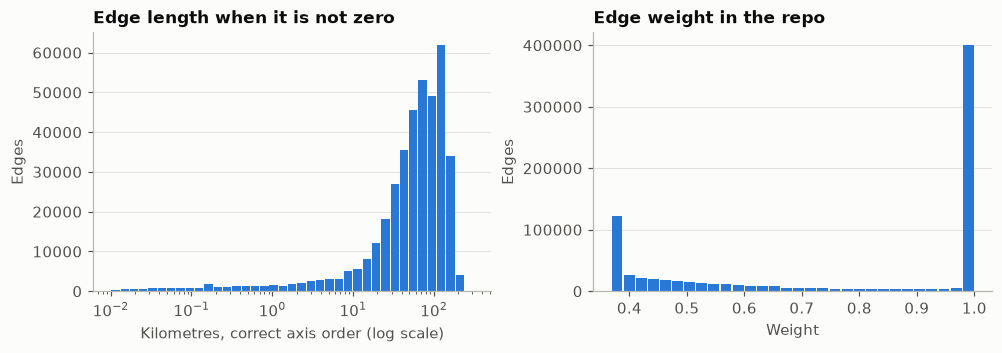

,Share
Edges with distance 0,48.6%
Edges with weight exactly 1,49.3%
Edges whose weight is set by the target node,36.1%
Edges whose weight is set by a node with one edge,31.1%


In [9]:
edges = np.array(graph.get_edgelist())
total_degree = np.array(graph.degree(mode="all"))
owner = edges.max(axis=1)
out_degree = np.array(graph.outdegree())
in_degree = np.array(graph.indegree())

mechanics = pd.Series(
    {
        "Edges with distance 0": (distance_repo == 0).mean(),
        "Edges with weight exactly 1": (weight_repo == 1).mean(),
        "Edges whose weight is set by the target node": (owner == edges[:, 1]).mean(),
        "Edges whose weight is set by a node with one edge": (total_degree[owner] == 1).mean(),
    }
).map("{:.1%}".format)
print("Weight range:", round(weight_repo.min(), 3), "to", round(weight_repo.max(), 3))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.1))
positive = distance_true[distance_true > 0]
axes[0].hist(positive, bins=np.logspace(-2, np.log10(positive.max()), 40), color=plots.BLUE, rwidth=0.9)
axes[0].set(xscale="log", title="Edge length when it is not zero", xlabel="Kilometres, correct axis order (log scale)", ylabel="Edges")
axes[0].grid(axis="x", visible=False)
axes[1].hist(weight_repo, bins=30, color=plots.BLUE, rwidth=0.9)
axes[1].set(title="Edge weight in the repo", xlabel="Weight", ylabel="Edges")
axes[1].grid(axis="x", visible=False)
plots.save(fig, "edge_length_and_weight")
plt.show()
mechanics.to_frame("Share")

**Interpretation:**

- **Weights are bounded, so the spatial bias is mild.** They can only range from 0.37 to 1, so one neighbour can be at most 2.7 times as likely as another.
- **About half the edges have no spatial information.** 48.6% have distance 0, usually because a flooded node shares the geometry of the node it inherited from. These get the highest weight.
- **The paper's per-node weight doesn't exist as such.** Each edge has one stored weight, and the repo's loop overwrites it, so the higher-numbered endpoint decides. For 36.1% of edges that is the target node, not the node the walk is leaving. For 31.1%, the deciding node has only this one edge, so the weight is 1 whatever the distance.

### Steps 6–7: walks and word2vec

In [10]:
class Holder:
    pass

holder = Holder()
holder.graph = Graph(directed=True, edges=[(0, 0), (0, 1), (1, 2)])
holder.graph.vs["name"] = ["monument", "city", "country"]
holder.graph.es["predicate"] = ["seeAlso", "locatedIn", "partOf"]
print("Walk without the self-loop:", GeoRDF2Vec.predicate_generation(holder, [1, 2]))
print("Walk with the self-loop:   ", GeoRDF2Vec.predicate_generation(holder, [0, 1, 2]))

walks = [[["a", "p", "b", "q", "c"]] * 50, [["b", "q", "c", "r", "d"]] * 50]
corpus = chain.from_iterable(walks)
model = Word2Vec(min_count=0, workers=1, seed=15, vector_size=20)
model.build_vocab(corpus)
before = model.wv.vectors.copy()
trained_words = model.train(corpus, total_examples=model.corpus_count, epochs=10)
print("\nWords in the vocabulary pass:", model.corpus_total_words)
print("Words the training pass saw: ", trained_words[1])
print("Vectors changed by training: ", not np.allclose(before, model.wv.vectors))
print("Defaults used by the repo: ", {"skip-gram": bool(model.sg), "window": model.window, "negative": model.negative})

direction = Graph(directed=True, edges=[(0, 1)])
print("\nigraph walk from the tail of edge 0->1:", direction.random_walk(start=0, steps=3))
print("igraph walk from the head of edge 0->1:", direction.random_walk(start=1, steps=3))

Walk without the self-loop: ['monument', 'locatedIn', 'city', 'partOf', 'country']
Walk with the self-loop:    ['monument', 'seeAlso', 'city', 'locatedIn', 'country', 'partOf', 'country']

Words in the vocabulary pass: 500
Words the training pass saw:  0
Vectors changed by training:  False
Defaults used by the repo:  {'skip-gram': False, 'window': 5, 'negative': 5}

igraph walk from the tail of edge 0->1: [0, 1]
igraph walk from the head of edge 0->1: [1]


**Interpretation:**

- **Walks only follow edges forwards.** igraph's `random_walk` defaults to outgoing edges and stops at a dead end, as the toy shows. The paper never states a direction, though its Eq. 7 over directed edges and its mention of walks reaching a "terminal node" fit this behaviour. Literals have no outgoing edges, so a walk ends at the first literal. Section 4 measures how much this shortens walks.
- **Self-loops corrupt the walk text.** `predicate_generation` removes the repeated node but not the repeated predicate, so every later predicate shifts by one: the walk above claims `city` is linked by `seeAlso`.
- **As committed, word2vec trains on nothing.** `corpus` is a one-shot iterator: `build_vocab` uses it up, and `train` then sees 0 words, leaving the vectors at their random starting values. We tested this with the same sequence of calls on a toy corpus under gensim 4.4. The paper's results can't have come from this exact code path, so the authors' version must have differed in some way we can't see.
- **The defaults answer a question the paper leaves open:** CBOW (not skip-gram), window 5, 5 negative samples, 200 dimensions, 10 epochs.

### Summary: what the code does beyond or differently from the paper

| Step | Location | What happens | Measured effect | For our baseline |
|---|---|---|---|---|
| Word2vec | `geo_rdf2vec.py`, `kg_training` | Iterator used up before training | **No training at all** | **Must fix** (`list(...)`) |
| Walks | `random_walk_iteration` | Outgoing edges only | Mean about 1.7 steps of 8 | Keep, report |
| Distance | `spatial_distance_calculation` | Longitude and latitude swapped | 46.3 km instead of 36.5 km | Keep, and test the fix as a variant |
| Geometry detection | `extract_geometry` | Misses `Point(` spelling | 8,357 geometries missed | Keep, and test the fix as a variant |
| Walk text | `predicate_generation` | Predicates shift after a self-loop | Affects walks taking a self-loop | Keep, report |
| Weights | `kg_training` | One weight per edge, last write wins | 36.1% set by the target | Keep, report |
| Flooding | `neighborhood_flood` | Correct, unlike Algorithm 1 | None | Keep |
| Parsing | `dmg_data_prep.py`, `read_kg_file` | Same-text nodes merge | 9,075 fewer nodes, 8,396 self-loops | Keep |

## 3. Basic exploratory analysis

### Degree and hubs

From here on, all analysis uses the repo's merged graph, because that is what walks actually see.

Merged graph: 148,127 entities and 184,067 literals
Nodes with no outgoing edge: 194,431 (58.5%)
Median total degree: 1; maximum: 65,576


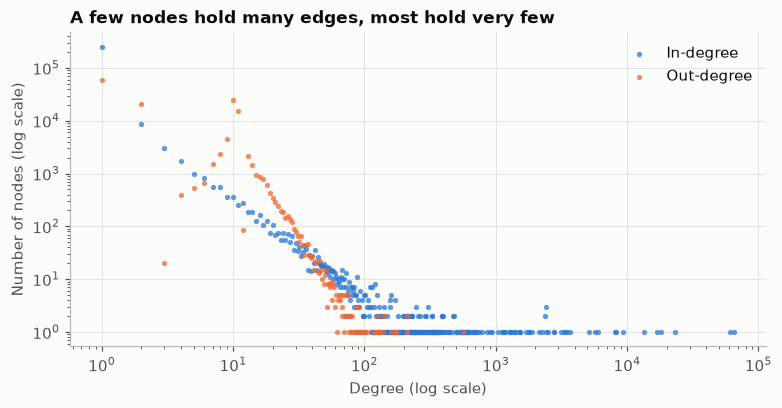

,node,kind,in,out,total
0,http://www.opengis.net/ont/geosparql#Geometry,Entity (IRI),65576,0,65576
1,https://data.labs.pdok.nl/rce/def/Afbeelding,Entity (IRI),60996,0,60996
2,zwart wit negatief,Language-tagged text,23232,0,23232
3,Fotocollectie,Language-tagged text,18146,0,18146
4,Collectie gebouwd,Language-tagged text,16868,0,16868
5,"Dukker, G.J.",Untyped text,13544,0,13544
6,"Wal, A.J. van der",Untyped text,9396,0,9396
7,true,Boolean,8230,0,8230
8,Agrarisch Erfgoed - Fotocollectie SHBO,Language-tagged text,8090,0,8090
9,Digitale opname,Language-tagged text,6023,0,6023


In [11]:
kinds = raw_nodes.groupby("label")["kind"].agg(lambda k: "Entity (IRI)" if "Entity (IRI)" in set(k) else sorted(set(k))[0])
node_kind = pd.Series(names).map(kinds).fillna("WKT geometry").to_numpy()
is_entity = node_kind == "Entity (IRI)"
print(f"Merged graph: {is_entity.sum():,} entities and {(~is_entity).sum():,} literals")
print(f"Nodes with no outgoing edge: {(out_degree == 0).sum():,} ({(out_degree == 0).mean():.1%})")
print(f"Median total degree: {np.median(total_degree):.0f}; maximum: {total_degree.max():,}")

fig, ax = plt.subplots(figsize=(7, 3.6))
for values, colour, title in ((in_degree, plots.BLUE, "In-degree"), (out_degree, plots.ORANGE, "Out-degree")):
    degree, count = np.unique(values[values > 0], return_counts=True)
    ax.scatter(degree, count, s=12, color=colour, label=title, alpha=0.75, linewidths=0)
ax.set(xscale="log", yscale="log", xlabel="Degree (log scale)", ylabel="Number of nodes (log scale)",
       title="A few nodes hold many edges, most hold very few")
ax.legend()
plots.save(fig, "degree_distribution")
plt.show()

hubs = pd.DataFrame({"node": names, "kind": node_kind, "in": in_degree, "out": out_degree, "total": total_degree})
hubs["node"] = hubs["node"].str.slice(0, 62)
hubs.nlargest(10, "total").reset_index(drop=True)

**Interpretation:** the distribution is heavy-tailed, as is typical of knowledge graphs. The median node has a single edge, while the largest hub has 65,576. 58.5% of nodes have no outgoing edge. The hubs are not places. They are classes (`Geometry`, `Afbeelding`, meaning "image") and shared literals (a film format, photographers' names). A random walk that reaches a hub learns little, and in Section 4 these same hubs are the source of meaningless flooded locations.

### Relations

60 relations; the top 5 cover 42.5% of edges
Relations with fewer than 100 edges: 6


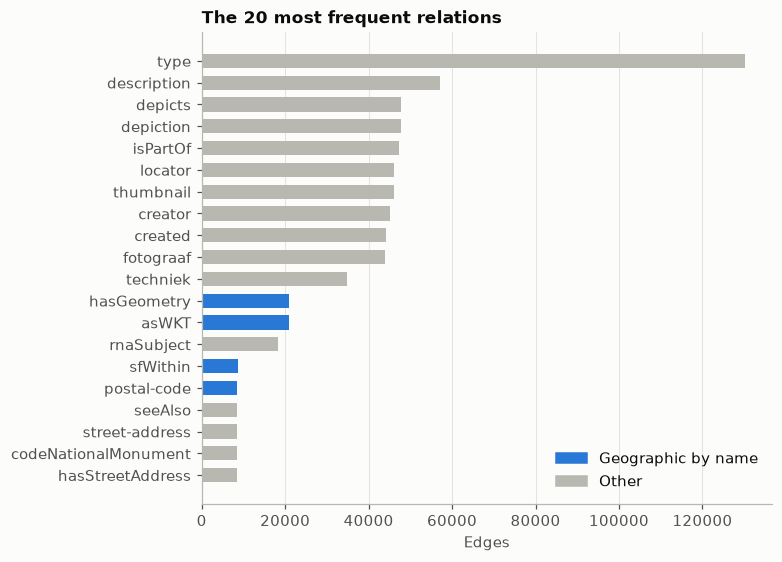

In [12]:
relation_counts = triples["predicate"].value_counts()
top = relation_counts.head(20).sort_values()
print(f"{len(relation_counts)} relations; the top 5 cover {relation_counts.head(5).sum() / len(triples):.1%} of edges")
print("Relations with fewer than 100 edges:", (relation_counts < 100).sum())
spatial_terms = ("geosparql", "geonames", "city", "wijken", "neighbourhood", "postal-code", "spatial")
colours = [plots.BLUE if any(term in iri for term in spatial_terms) else plots.NEUTRAL for iri in top.index]
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh([short(iri) for iri in top.index], top.values, color=colours, height=0.65)
ax.set(xlabel="Edges", title="The 20 most frequent relations")
ax.grid(axis="y", visible=False)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=plots.BLUE), plt.Rectangle((0, 0), 1, 1, color=plots.NEUTRAL)],
          labels=["Geographic by name", "Other"], loc="lower right")
plots.save(fig, "relation_frequency")
plt.show()

**Interpretation:** usage is uneven: the top 5 of 60 relations cover 42.5% of edges, and 6 relations have fewer than 100 edges. Much of the graph describes photographs rather than monuments (`creator`, `created`, `fotograaf`, meaning "photographer"). Only some relations look geographic by name. Section 4 tests that by measurement rather than by name.

### Labels and splits

Largest-class accuracy on validation: 0.478
Monument appears in more than one split: 0


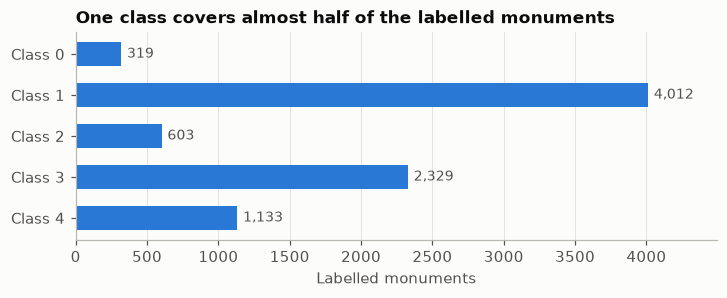

split,train,valid,test,total,share
class,,,,,
0,205,38,76,319,3.8%
1,2578,478,956,4012,47.8%
2,387,72,144,603,7.2%
3,1496,278,555,2329,27.7%
4,728,135,270,1133,13.5%


In [13]:
class_table = labels.pivot_table(index="class", columns="split", values="index", aggfunc="count")[["train", "valid", "test"]]
class_table["total"] = class_table.sum(axis=1)
class_table["share"] = (class_table["total"] / class_table["total"].sum()).map("{:.1%}".format)
print("Largest-class accuracy on validation:", f"{(labels[labels.split == 'valid']['class'] == labels[labels.split == 'train']['class'].mode()[0]).mean():.3f}")
print("Monument appears in more than one split:", labels["index"].duplicated().sum())

totals = class_table["total"].sort_index(ascending=False)
fig, ax = plt.subplots(figsize=(6.5, 2.6))
ax.barh([f"Class {c}" for c in totals.index], totals.values, color=plots.BLUE, height=0.6)
for y, value in enumerate(totals.values):
    ax.text(value + 40, y, f"{value:,}", va="center", color=plots.MUTED, fontsize=9)
ax.set(title="One class covers almost half of the labelled monuments", xlabel="Labelled monuments")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, totals.max() * 1.12)
plots.save(fig, "class_balance")
plt.show()
class_table

**Interpretation:** classes are imbalanced, from 3.8% to 47.8%, so accuracy alone flatters a model: always guessing class 1 scores 0.478. Macro F1 is the fairer metric, and the paper reports it too. The class shares are the same in each split, and no monument appears twice. The class names are not in the data.

### Label leakage

If the graph contained the answer, any method would look good. We checked the target relation directly, then searched for graph features that nearly determine the class, using the training split only.

In [14]:
print("Triples using the target relation monumentCode:", triples["predicate"].str.contains("monumentCode").sum())
print("Triples using dcterms:subject, removed by the dataset authors:", triples["predicate"].eq("http://purl.org/dc/terms/subject").sum())

labelled = triples.merge(labels[["node", "class", "split"]], left_on="subject", right_on="node")
train_rows = labelled[labelled["split"] == "train"]
pair_stats = train_rows.groupby(["predicate", "object"])["class"].agg(support="size", purity=lambda c: c.value_counts(normalize=True).iloc[0], top_class=lambda c: c.mode()[0]).reset_index()
pure = pair_stats[(pair_stats["support"] >= 20) & (pair_stats["purity"] >= 0.95)]
valid_rows = labelled[labelled["split"] == "valid"].merge(pure, on=["predicate", "object"])
valid_prediction = valid_rows.groupby("subject").agg(prediction=("top_class", lambda c: c.mode()[0]), truth=("class", "first"))
n_valid = (labels["split"] == "valid").sum()
print(f"Graph features with 95%+ purity in training (20+ monuments): {len(pure)}")
print(f"They apply to {len(valid_prediction)} of {n_valid} validation monuments ({len(valid_prediction) / n_valid:.1%}); accuracy there: {(valid_prediction['prediction'] == valid_prediction['truth']).mean():.3f}")
view = pure.sort_values("support", ascending=False).head(8).copy()
view["predicate"] = view["predicate"].map(short)
view["object"] = view["object"].str.slice(0, 50)
view["purity"] = view["purity"].round(3)
view.reset_index(drop=True)

Triples using the target relation monumentCode: 0
Triples using dcterms:subject, removed by the dataset authors: 0


Graph features with 95%+ purity in training (20+ monuments): 23
They apply to 13 of 1001 validation monuments (1.3%); accuracy there: 0.692


,predicate,object,support,purity,top_class
0,sfWithin,https://data.labs.pdok.nl/cbs/id/gemeente/GM0687,346,0.957,1
1,city,http://sws.geonames.org/2750896/,344,0.959,1
2,city,http://sws.geonames.org/2751792/,207,0.952,1
3,city,http://sws.geonames.org/2754135/,51,1.000,1
4,city,http://sws.geonames.org/2755476/,50,0.960,1
5,hasStreetAddress,Herengracht,44,0.955,1
6,sfWithin,https://data.labs.pdok.nl/cbs/id/gemeente/GM0180,36,1.000,3
7,hasStreetAddress,Lange Haven,28,0.964,1


**Interpretation:** we found **no leakage**. The target relation `monumentCode` and the related `dcterms:subject`, which the dataset authors removed according to their scripts, are both absent. Near-pure features exist, but they are ordinary places and streets, cover only 1.3% of validation monuments, and score only 0.692 there. We did not test whether the free-text descriptions hint at the class, but walks treat a text as one opaque node, so they can't read its words.

### Missing data

In [15]:
has_geometry = triples[triples["predicate"].str.endswith("#hasGeometry")]
as_wkt = triples[triples["predicate"].str.endswith("#asWKT")].set_index("subject")["object"]
linked = has_geometry.assign(wkt=has_geometry["object"].map(as_wkt))
print(f"hasGeometry targets with no WKT literal: {linked['wkt'].isna().sum()} triples")
linked = linked.dropna(subset=["wkt"])
linked["geometry"] = sp.parse_geometries(linked["wkt"].map(sp.extract_wkt))
linked["type"] = shapely.get_type_id(linked["geometry"].to_numpy())
own = linked.groupby("subject")["geometry"].agg(lambda g: sp.collection_centroid(g.to_numpy())).to_frame("centroid")
own["lon"] = own["centroid"].str[0]
own["lat"] = own["centroid"].str[1]
own["geometries"] = linked.groupby("subject").size()
own = own.drop(columns="centroid")

entity_names = pd.Series(names)[is_entity]
def namespace(iri: str) -> str:
    parts = iri.split("/")
    return "/".join(parts[2:6]) if parts[2] != "sws.geonames.org" else parts[2]
groups = entity_names.map(namespace)
coverage = pd.DataFrame({"namespace": groups.values, "located": entity_names.isin(own.index).values, "geometry_node": entity_names.isin(as_wkt.index).values})
coverage_table = coverage.groupby("namespace").agg(entities=("located", "size"), own_geometry=("located", "sum"), geometry_nodes=("geometry_node", "sum")).sort_values("entities", ascending=False)

labels_located = labels.merge(own, left_on="node", right_index=True, how="left")
print(f"Labelled monuments with their own geometry: {labels_located['lon'].notna().sum():,} of {len(labels):,}")
print(f"Entities with their own geometry: {is_entity[[vertex_of[s] for s in own.index]].sum():,}, plus {len(as_wkt.index.unique()):,} geometry nodes, out of {is_entity.sum():,} entities")
print("Geometries per labelled monument:", labels_located["geometries"].value_counts().sort_index().head(6).to_dict())

unlinked = [n for n in entity_names[groups == "bag.basisregistraties.overheid.nl/bag/id/geometry"] if n not in as_wkt.index]
unlinked_set = set(unlinked)
print(f"\nBAG geometry entities without WKT: {len(unlinked):,}")
print("Edges into them:", triples.loc[triples["object"].isin(unlinked_set), "predicate"].map(short).value_counts().to_dict())
print("Edges out of them:", triples.loc[triples["subject"].isin(unlinked_set), "predicate"].map(short).value_counts().to_dict())
coverage_table.head(6)

hasGeometry targets with no WKT literal: 5 triples


Labelled monuments with their own geometry: 8,396 of 8,396
Entities with their own geometry: 10,303, plus 20,866 geometry nodes, out of 148,127 entities
Geometries per labelled monument: {1: 8, 2: 6641, 3: 1322, 4: 308, 5: 83, 6: 23}

BAG geometry entities without WKT: 44,710
Edges into them: {}
Edges out of them: {'type': 44710}


,entities,own_geometry,geometry_nodes
namespace,,,
data.labs.pdok.nl/rce/id/image,60996,0,0
bag.basisregistraties.overheid.nl/bag/id/geometry,55283,0,10573
data.labs.pdok.nl/rce/id/monument,8396,8396,0
sws.geonames.org,5913,1536,1536
data.labs.pdok.nl/cbs/id/gemeente,392,371,0
data.pldn.nl/cbs/wijken-buurten/regios,373,0,371


In [16]:
weak = graph.connected_components(mode="weak")
entity_graph = graph.induced_subgraph(np.flatnonzero(is_entity))
entity_components = np.array(entity_graph.connected_components(mode="weak").sizes())
print(f"Weakly connected components: {len(weak)} (largest {max(weak.sizes()):,} nodes)")
print(f"Entities only: {len(entity_components):,} components, largest {entity_components.max():,}, of which singletons {(entity_components == 1).sum():,}")

Weakly connected components: 1 (largest 332,194 nodes)
Entities only: 1 components, largest 148,127, of which singletons 0


**Interpretation:**

- **No labelled monument lacks a geometry.** All 8,396 have one, and 99.9% have two or more (typically a building polygon and a point). So the choice of centroid affects nearly every monument.
- **Most entities have no geometry of their own.** That is the gap flooding has to fill. Images are the largest group at 60,996. Of these, 47,872 get a location at round 3, next to located entities, and the other 13,124 only at round 5, through the `Afbeelding` class hub.
- **44,710 geometry nodes are empty stubs.** They have no WKT and no incoming edge, and their only edge is `type → Geometry`. They connect to the graph only through that class hub.
- **The graph has one connected component,** even without literals. So no node is cut off from flooding, as the brief feared some might be.

## 4. Specific analysis, tied to our planned contributions

### Geometry quality

In [17]:
type_names = {0: "Point", 3: "Polygon", 6: "MultiPolygon"}
wgs_wkt = triples.loc[triples["predicate"].str.endswith("#asWKT"), "object"].drop_duplicates()
wgs_geometries = sp.parse_geometries(wgs_wkt.map(sp.extract_wkt))
type_counts = pd.Series(shapely.get_type_id(wgs_geometries)).map(type_names).value_counts().rename("WGS84 literals").to_frame()
rd_rows = triples[triples["predicate"].str.endswith("#asWKT-RD")]
rd_geometries = sp.parse_geometries(rd_rows["object"].map(sp.extract_wkt))
type_counts["RD New literals (converted)"] = pd.Series(shapely.get_type_id(rd_geometries)).map(type_names).value_counts()
type_counts = type_counts.fillna(0).astype(int)

invalid = ~shapely.is_valid(wgs_geometries)
centres = shapely.centroid(wgs_geometries)
west, south, east, north = sp.NL_BBOX
outside = ~((shapely.get_x(centres) > west) & (shapely.get_x(centres) < east) & (shapely.get_y(centres) > south) & (shapely.get_y(centres) < north))
print(f"Invalid geometries: {invalid.sum()}   Empty: {shapely.is_empty(wgs_geometries).sum()}   Centre outside the Netherlands box: {outside.sum()}")

rd_nodes = rd_rows.set_index("subject")["object"]
both = rd_nodes.index.intersection(as_wkt.index)
rd_centres = shapely.centroid(sp.parse_geometries(rd_nodes.loc[both].map(sp.extract_wkt)))
wgs_centres = shapely.centroid(sp.parse_geometries(as_wkt.loc[both].map(sp.extract_wkt)))
gap = sp.geodesic_km(shapely.get_x(rd_centres), shapely.get_y(rd_centres), shapely.get_x(wgs_centres), shapely.get_y(wgs_centres)) * 1000
rd_owners = has_geometry[has_geometry["object"].isin(rd_nodes.index)]["subject"]
print(f"RD New geometry nodes: {len(rd_nodes)}; also have a WGS84 literal: {len(both)}")
print(f"Centre gap between converted RD New and WGS84: median {np.median(gap):.1f} m, maximum {gap.max():.1f} m")
print("Owners of the RD New geometries:", rd_owners.str.extract(r"/id/([a-z]+)/")[0].value_counts().to_dict())
type_counts

Invalid geometries: 1   Empty: 0   Centre outside the Netherlands box: 0


RD New geometry nodes: 371; also have a WGS84 literal: 371
Centre gap between converted RD New and WGS84: median 0.1 m, maximum 0.2 m
Owners of the RD New geometries: {'gemeente': 371}


,WGS84 literals,RD New literals (converted)
Polygon,10894,321
Point,9893,0
MultiPolygon,50,50


**Interpretation:** the geometries are clean: one invalid shape, none empty, and none centred outside the Netherlands. **The RD New conversion adds nothing new.** All 371 RD New geometries belong to municipalities, each also has a WGS84 version, and after conversion their centres differ by at most 0.2 m. That confirms the conversion works and shows it is redundant. These 371 geometry nodes simply end up with two copies of the same shape.

### Where the monuments are

The background map is drawn from the dataset's own municipality shapes. Only 371 of 392 municipalities have one, so blank areas on land mean a missing shape, not missing monuments.

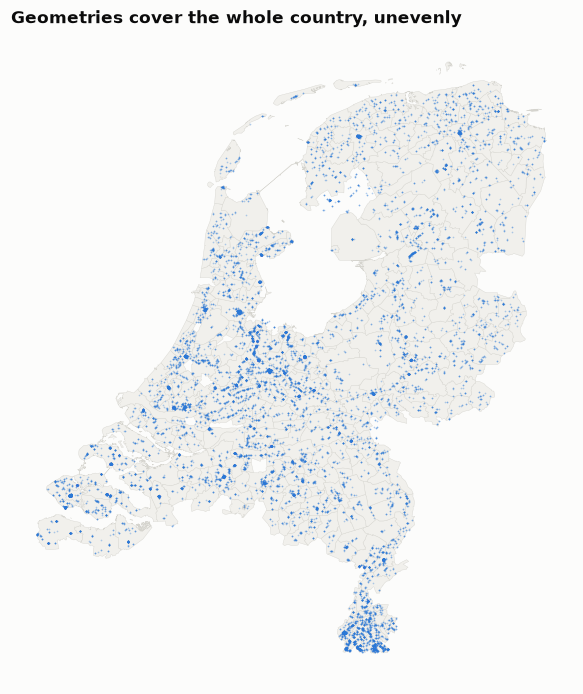

In [18]:
municipalities = gpd.GeoDataFrame(geometry=sp.parse_geometries(rd_rows["object"].map(sp.extract_wkt)), crs=4326).simplify(0.002)

def draw_base(ax):
    municipalities.plot(ax=ax, facecolor="#f1f0ec", edgecolor="#d5d4ce", linewidth=0.25, rasterized=True)
    ax.set_axis_off()
    ax.set_aspect(1.6)

fig, ax = plt.subplots(figsize=(6, 6.2))
draw_base(ax)
ax.scatter(shapely.get_x(centres), shapely.get_y(centres), s=1.2, color=plots.BLUE, alpha=0.35, linewidths=0, rasterized=True)
ax.set_title("Geometries cover the whole country, unevenly")
plots.save(fig, "map_all_geometries")
plt.show()

**Interpretation:** coverage is national but uneven, with visible lines along rivers and in historic centres, and a dense cluster in South Limburg. An analysis that weights all areas equally would over-represent these clusters.

### Does location relate to the class?

This is the central assumption behind GeoRDF2Vec. We test it on the validation split, using a classifier that sees only coordinates. Shuffling the training labels shows what chance looks like.

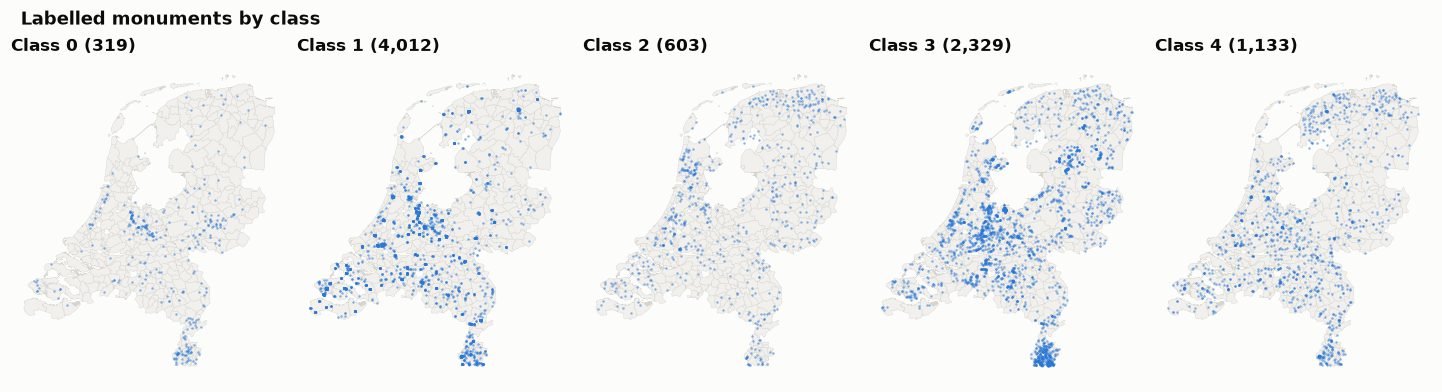

Class by map cell (0.25 degrees, 30+ monuments): 67 cells, chi-square p = 0.0e+00, Cramér's V = 0.30
Class shares in the far south (latitude below 51): {0: 0.052, 1: 0.447, 2: 0.031, 3: 0.359, 4: 0.112} of 949 monuments


,Accuracy,Macro F1
Always predict the largest class,0.478,0.129
"Nearest 5 monuments, coordinates only",0.332,0.262
"Nearest 15 monuments, coordinates only",0.336,0.259
"Nearest 50 monuments, coordinates only",0.359,0.238
"Nearest 15 monuments, shuffled training labels",0.335,0.133


In [19]:
fig, axes = plt.subplots(1, 5, figsize=(13, 3.5))
for class_id, ax in enumerate(axes):
    draw_base(ax)
    subset = labels_located[labels_located["class"] == class_id]
    ax.scatter(subset["lon"], subset["lat"], s=2.5, color=plots.BLUE, alpha=0.55, linewidths=0, rasterized=True)
    ax.set_title(f"Class {class_id} ({len(subset):,})")
fig.suptitle("Labelled monuments by class", x=0.01, ha="left", fontweight="bold")
plots.save(fig, "map_by_class")
plt.show()

train = labels_located[labels_located["split"] == "train"]
valid = labels_located[labels_located["split"] == "valid"]
majority = train["class"].mode()[0]
results = {"Always predict the largest class": np.full(len(valid), majority)}
for k in (5, 15, 50):
    knn = KNeighborsClassifier(n_neighbors=k).fit(train[["lon", "lat"]], train["class"])
    results[f"Nearest {k} monuments, coordinates only"] = knn.predict(valid[["lon", "lat"]])
shuffled = np.random.default_rng(0).permutation(train["class"].to_numpy())
results["Nearest 15 monuments, shuffled training labels"] = KNeighborsClassifier(n_neighbors=15).fit(train[["lon", "lat"]], shuffled).predict(valid[["lon", "lat"]])

cells = labels_located.assign(cell=(labels_located["lon"] / 0.25).round().astype(int).astype(str) + "_" + (labels_located["lat"] / 0.25).round().astype(int).astype(str))
big_cells = cells[cells.groupby("cell")["class"].transform("size") >= 30]
contingency = pd.crosstab(big_cells["cell"], big_cells["class"])
chi2, p_value, *_ = chi2_contingency(contingency)
cramers_v = np.sqrt(chi2 / (contingency.to_numpy().sum() * (min(contingency.shape) - 1)))
print(f"Class by map cell (0.25 degrees, 30+ monuments): {contingency.shape[0]} cells, chi-square p = {p_value:.1e}, Cramér's V = {cramers_v:.2f}")
limburg = labels_located["lat"] < 51.0
print("Class shares in the far south (latitude below 51):", labels_located.loc[limburg, "class"].value_counts(normalize=True).sort_index().round(3).to_dict(), f"of {limburg.sum()} monuments")
pd.DataFrame(
    {name: {"Accuracy": accuracy_score(valid["class"], p), "Macro F1": f1_score(valid["class"], p, average="macro", zero_division=0)} for name, p in results.items()}
).T.round(3)

**Interpretation: yes, but modestly.**

- Class varies by place: the association is highly significant, with a moderate effect size (Cramér's V = 0.30).
- Coordinates alone **do not beat always guessing the largest class on accuracy** (0.33–0.36 vs 0.478). Even shuffled labels score 0.335, which is simply what guessing in proportion to class sizes achieves.
- Macro F1 does show signal: 0.259 with real labels against 0.133 with shuffled ones.

Location helps tell classes apart, but it won't decide the class by itself, so its value should come from combining with the graph's other facts. This also limits what we should expect from purely spatial changes to the walks. These validation scores are not directly comparable with the paper's test-set scores.

### Which relations are spatial?

This is the evidence for **relation-aware flooding**. For each relation, we group located entities that share an object, such as monuments with the same postal code, and measure how far each sits from its group's centre. Only entities' own geometries are used, so flooding cannot influence the result. For scale, a located entity sits a median of 75 km from the national mean position.

Baseline, distance of a located entity to the national mean position: 75.3 km (median)


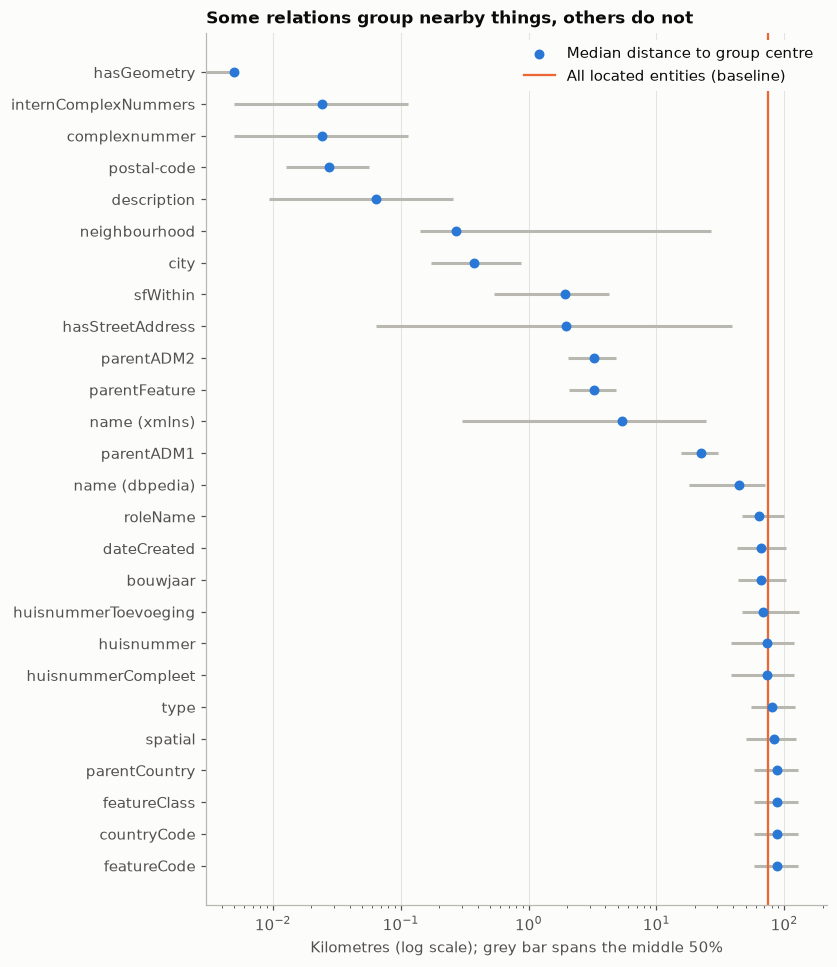

,rows,groups,median
hasGeometry,302,134,0.00
complexnummer,224,84,0.02
internComplexNummers,224,84,0.02
postal-code,3904,1354,0.03
description,351,127,0.06
neighbourhood,205,40,0.27
city,7793,933,0.37
sfWithin,8749,359,1.93
hasStreetAddress,6207,1169,1.97
parentADM2,1428,303,3.25


In [20]:
all_points = own[["lon", "lat"]]
overall = sp.geodesic_km(all_points["lon"].to_numpy(), all_points["lat"].to_numpy(), np.full(len(all_points), all_points["lon"].mean()), np.full(len(all_points), all_points["lat"].mean()))
baseline_km = np.median(overall)
dispersion = sp.relation_dispersion(triples, own["lon"], own["lat"], min_rows=200)
hosts = dispersion.index.str.extract(r"//(?:www\.)?([^./]+)")[0].to_numpy()
short_names = dispersion.index.map(short)
repeated = short_names.duplicated(keep=False)
dispersion.index = [f"{name} ({host})" if twice else name for name, host, twice in zip(short_names, hosts, repeated)]
print(f"Baseline, distance of a located entity to the national mean position: {baseline_km:.1f} km (median)")

ordered = dispersion.sort_values("median", ascending=False)
fig, ax = plt.subplots(figsize=(7.5, 0.28 * len(ordered) + 1.4))
y = np.arange(len(ordered))
ax.hlines(y, ordered["q25"].clip(lower=0.005), ordered["q75"], color=plots.NEUTRAL, linewidth=2)
ax.scatter(ordered["median"].clip(lower=0.005), y, s=30, color=plots.BLUE, zorder=3, label="Median distance to group centre")
ax.axvline(baseline_km, color=plots.ORANGE, linewidth=1.5, label="All located entities (baseline)")
ax.set_yticks(y, ordered.index)
ax.set(xscale="log", xlabel="Kilometres (log scale); grey bar spans the middle 50%", title="Some relations group nearby things, others do not")
ax.grid(axis="y", visible=False)
ax.legend(loc="upper right", frameon=True, framealpha=1, facecolor=plots.SURFACE, edgecolor="none")
plots.save(fig, "relation_spatial_dispersion")
plt.show()
dispersion[["rows", "groups", "median"]].round(2)

**Interpretation:** relations fall into clear groups.

- **Spatial:** `complexnummer`, `postal-code`, `neighbourhood`, `city`, `sfWithin` (from 20 m to 2 km).
- **Regional:** `parentADM2` (3 km), `parentADM1` (22 km). `parentCountry` is at the national baseline by definition.
- **Not spatial:** `bouwjaar` (build year), `dateCreated`, `huisnummer` (house number), `type`, at 66–81 km, close to the 75 km baseline.

That postal codes are local and build years are not is expected. The chart's use is to replace guesses with a measured relation list for **relation-aware flooding**, since the repo floods across a house number or build year just like `city`. The possible benefit has a limit: labelled monuments have their own geometry, so this cannot move them. It can only change the locations of the nodes around them, and through those, the edge weights. We have not yet measured how much that matters.

The analysis has limits. It only sees relations whose subjects have their own geometry, so photo relations such as `creator` are absent. A group with one member contributes nothing, so relations with mostly unique objects are also absent.

### How far does flooding have to travel?

Hop of labelled monuments: {np.int32(2): np.int64(8396)}
Hop of a monument if Point spelling is fixed: {np.int32(2): np.int64(8396)}
Monument location shift when Point spelling is fixed: median 0.000 km, 99th percentile 0.000 km, maximum 0.000 km
Edges whose length changes by more than 1 km when Point spelling is fixed: 16,772 (2.2%)
Mean km on those edges, by relation (repo, then fixed):


             edges  repo  fixed
relation                       
hasGeometry   8386  90.9    0.0
type          8386   0.0   90.9

Round 5 entities by namespace: {'data.labs.pdok.nl/rce/id/image': 13124}


Rounds of image entities: {np.int32(3): np.int64(47872), np.int32(5): np.int64(13124)}


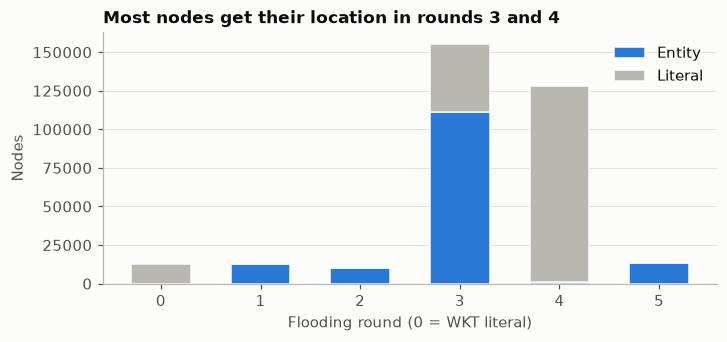

kind,Entity,Literal,Share of nodes
hop,,,
0,0,12851,3.9%
1,12480,0,3.8%
2,10305,0,3.1%
3,111316,43780,46.7%
4,902,127436,38.6%
5,13124,0,4.0%


In [21]:
hop_table = pd.DataFrame({"hop": repo_flood.hops, "kind": np.where(is_entity, "Entity", "Literal")}).value_counts().unstack(fill_value=0).sort_index()
hop_table["Share of nodes"] = (hop_table.sum(axis=1) / graph.vcount()).map("{:.1%}".format)
labelled_vertices = np.array([vertex_of[n] for n in labels["node"]])
print("Hop of labelled monuments:", dict(zip(*np.unique(repo_flood.hops[labelled_vertices], return_counts=True))))
print("Hop of a monument if Point spelling is fixed:", dict(zip(*np.unique(fixed_flood.hops[labelled_vertices], return_counts=True))))
shift = sp.geodesic_km(repo_x[labelled_vertices], repo_y[labelled_vertices], fixed_x[labelled_vertices], fixed_y[labelled_vertices])
print(f"Monument location shift when Point spelling is fixed: median {np.median(shift):.3f} km, 99th percentile {np.percentile(shift, 99):.3f} km, maximum {shift.max():.3f} km")

changed = np.abs(distance_true - distance_fixed) > 1
edge_predicates = pd.Series(graph.es["predicate"]).map(short)
print(f"Edges whose length changes by more than 1 km when Point spelling is fixed: {changed.sum():,} ({changed.mean():.1%})")
print("Mean km on those edges, by relation (repo, then fixed):")
print(pd.DataFrame({"relation": edge_predicates[changed], "repo": distance_true[changed], "fixed": distance_fixed[changed]}).groupby("relation").agg(edges=("repo", "size"), repo=("repo", "mean"), fixed=("fixed", "mean")).round(1).to_string())
last_round = pd.Series(names)[repo_flood.hops == 5]
print("\nRound 5 entities by namespace:", last_round.map(namespace).value_counts().head(3).to_dict())
image_nodes = pd.Series(names)[pd.Series(names).str.contains("/rce/id/image/")]
print("Rounds of image entities:", dict(zip(*np.unique(repo_flood.hops[image_nodes.index], return_counts=True))))

fig, ax = plt.subplots(figsize=(6.5, 3))
bottom = np.zeros(len(hop_table))
for column, colour in (("Entity", plots.BLUE), ("Literal", plots.NEUTRAL)):
    ax.bar(hop_table.index, hop_table[column], bottom=bottom, color=colour, width=0.6, label=column, edgecolor=plots.SURFACE, linewidth=1)
    bottom += hop_table[column].to_numpy()
ax.set(xlabel="Flooding round (0 = WKT literal)", ylabel="Nodes", title="Most nodes get their location in rounds 3 and 4")
ax.grid(axis="x", visible=False)
ax.legend()
plots.save(fig, "flooding_rounds")
plt.show()
hop_table

**Interpretation:**

- **Most locations are assigned at rounds 3 and 4.** 85% of nodes get theirs there, three or four hops from a WKT literal. Round 1 is geometry nodes, and round 2 includes all labelled monuments. Monuments know their location, so these two rounds are just the path to the coordinates.
- **The `Point` spelling problem is mostly invisible in the averages.** Monument locations do not move at all, because polygons outrank points in a centroid and every labelled monument has a recognised geometry. The mean edge length also stays the same. But 2.2% of edge lengths change, in two groups that cancel out exactly: 8,386 `hasGeometry` edges to `Point` nodes go from 90.9 km to 0, and 8,386 `type` edges from those nodes go from 0 to 90.9 km. So the bug does change which edges a weighted walk prefers: it discourages the step from a monument to its own point.

### What locations do hubs inherit?

This is the evidence for **better aggregation of inherited geometries**.

Nodes inheriting one geometry: 61.6%; more than 100: 75,620; all 12,851: 61,454 (18.5%)
National-centre nodes by kind: {'Entity (IRI)': 53097, 'WKT geometry': 8357}
Rounds of those nodes: {np.int32(2): np.int64(1), np.int32(3): np.int64(53096), np.int32(4): np.int64(8357)}
Entities among them by namespace: {'bag.basisregistraties.overheid.nl/bag/id/geometry': 44710, 'data.labs.pdok.nl/.well-known/genid/7a2e7530-395c-11e8-88f3-54e1adc08017': 1, 'data.labs.pdok.nl/.well-known/genid/7344c2a6-395c-11e8-b8a6-54e1adc08017': 1}
Share of those entities typed geosparql:Geometry: 1.0
Centroid of every such node: 5.622 52.237 (longitude, latitude)
Edges with one end at the national centre: 10.6%


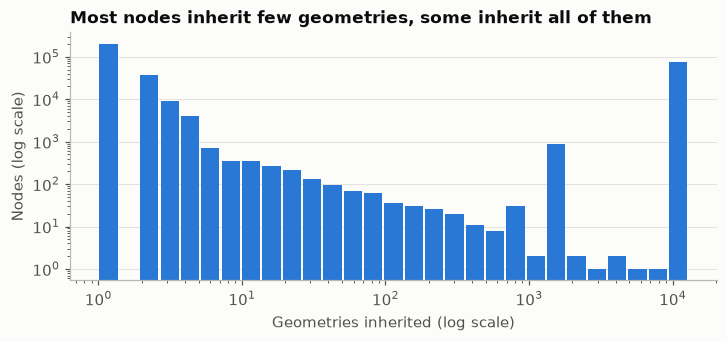

,node,kind,round,degree,geometries,median km to inherited geometries
0,http://www.opengis.net/ont/geosparql#Geometry,Entity (IRI),2,65576,12851,84.0
1,https://data.labs.pdok.nl/rce/def/Afbeelding,Entity (IRI),4,60996,10573,72.7
2,http://www.geonames.org/ontology#P,Entity (IRI),3,2407,1536,87.9
3,http://sws.geonames.org/2750405/,Entity (IRI),3,2407,1536,87.9
4,http://www.geonames.org/ontology#Feature,Entity (IRI),3,2407,1536,87.9
5,http://www.geonames.org/ontology#P.PPL,Entity (IRI),3,2382,1517,88.1
6,https://data.pldn.nl/cbs/wijken-buurten/regios/2016/id/,Entity (IRI),3,392,742,78.5
7,http://www.opengis.net/ont/geosparql#Feature,Entity (IRI),3,388,742,78.5
8,https://data.pldn.nl/cbs/wijken-buurten/def/cbs#Gemeent,Entity (IRI),3,387,742,78.5
9,http://www.opengis.net/ont/gml#MultiSurface,Entity (IRI),2,371,742,78.5


In [22]:
n_sources = repo_flood.n_sources
all_inherit = n_sources == len(repo_seeds)
print(f"Nodes inheriting one geometry: {(n_sources == 1).mean():.1%}; more than 100: {(n_sources > 100).sum():,}; all {len(repo_seeds):,}: {all_inherit.sum():,} ({all_inherit.mean():.1%})")
print("National-centre nodes by kind:", pd.Series(node_kind[all_inherit]).value_counts().head(4).to_dict())
print("Rounds of those nodes:", dict(zip(*np.unique(repo_flood.hops[all_inherit], return_counts=True))))
all_names = pd.Series(names)[all_inherit]
print("Entities among them by namespace:", all_names[is_entity[all_inherit]].map(namespace).value_counts().head(3).to_dict())
one_edge_from_class = set(triples.loc[triples["object"].eq("http://www.opengis.net/ont/geosparql#Geometry"), "subject"])
print("Share of those entities typed geosparql:Geometry:", round(all_names[is_entity[all_inherit]].isin(one_edge_from_class).mean(), 3))
print("Centroid of every such node:", round(repo_x[all_inherit][0], 3), round(repo_y[all_inherit][0], 3), "(longitude, latitude)")
print("Edges with one end at the national centre:", f"{(all_inherit[edges[:, 0]] | all_inherit[edges[:, 1]]).mean():.1%}")

source_centres = shapely.centroid(repo_geometries)
source_x, source_y = shapely.get_x(source_centres), shapely.get_y(source_centres)
def spread_km(vertex: int) -> float:
    members = repo_flood.sets[repo_flood.set_id[vertex]]
    return float(np.median(sp.geodesic_km(source_x[members], source_y[members], np.full(len(members), repo_x[vertex]), np.full(len(members), repo_y[vertex]))))

biggest = pd.DataFrame({"node": names, "kind": node_kind, "round": repo_flood.hops, "degree": total_degree, "geometries": n_sources})
biggest = biggest[is_entity & (n_sources > 1)].nlargest(10, "degree")
biggest["median km to inherited geometries"] = [round(spread_km(v), 1) for v in biggest.index]
biggest["node"] = biggest["node"].str.slice(0, 55)

fig, ax = plt.subplots(figsize=(6.5, 3))
ax.hist(n_sources, bins=np.logspace(0, np.log10(n_sources.max() + 1), 30), color=plots.BLUE, rwidth=0.9)
ax.set(xscale="log", yscale="log", xlabel="Geometries inherited (log scale)", ylabel="Nodes (log scale)", title="Most nodes inherit few geometries, some inherit all of them")
ax.grid(axis="x", visible=False)
plots.save(fig, "inherited_geometries")
plt.show()
biggest.reset_index(drop=True)

**Interpretation:** 61.6% of nodes inherit one geometry, which is a sensible location. But **61,454 nodes (18.5%) inherit all 12,851 recognised geometries**, so they all sit at one point near the middle of the country (5.62°E, 52.24°N). The cause is the `Geometry` class hub. It inherits everything in round 2 and passes it to every node typed as a geometry that has not yet been located: the 44,710 stubs and the `Point` geometry nodes. Their `Point` literals follow in round 4.

For the largest hubs, the median inherited geometry lies 70–90 km from the assigned centroid, about the same as the national baseline, so that centroid says nothing. 10.6% of edges touch one of these national-centre nodes. Excluding class hubs from flooding, or keeping several locations instead of one centroid, would directly address this. Our planned relation-aware flooding would do so too, if `type` is excluded.

### Do walks drift? Do they even get long enough?

This is the evidence for **adaptive walk length** and **locality-aware walks**. We simulated 10 walks of up to 8 steps from each of 1,000 random labelled monuments, following igraph's rules, and compared uniform and repo weights. Distances use the corrected axis order and spelling, so they measure real geography.

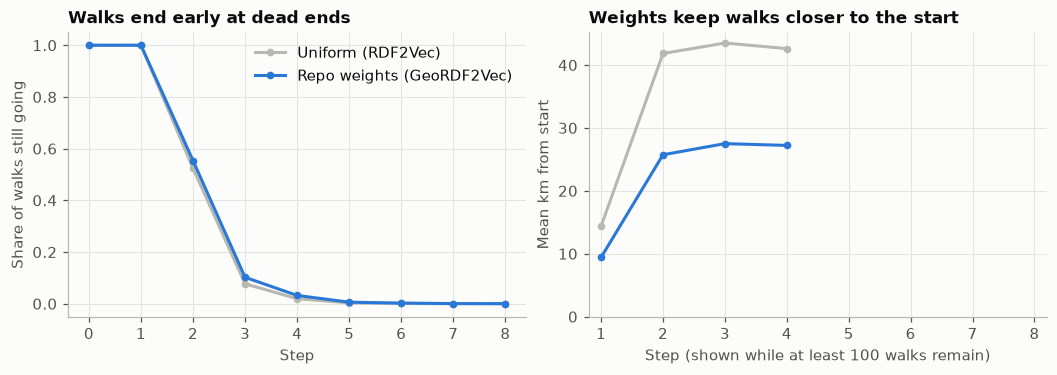

Check with igraph's own random_walk, uniform: mean 1.613 steps, longest 4
Longest simulated walk: {'Uniform (RDF2Vec)': 8, 'Repo weights (GeoRDF2Vec)': 8}
Mean km from start per step: {'Uniform (RDF2Vec)': [np.float64(14.4), np.float64(41.8), np.float64(43.5), np.float64(42.6), None, None, None, None], 'Repo weights (GeoRDF2Vec)': [np.float64(9.4), np.float64(25.7), np.float64(27.5), np.float64(27.2), None, None, None, None]}


,Uniform (RDF2Vec),Repo weights (GeoRDF2Vec)
Mean steps taken (of 8),1.6251,1.6974
Walks reaching all 8 steps,0.0001,0.0003
Walks ending on a literal,0.8204,0.8613
Steps that are self-loops,0.0407,0.0461
Steps landing on a node already visited,0.0566,0.0736


In [23]:
rng = np.random.default_rng(7)
starts = rng.choice(labelled_vertices, size=1000, replace=False)
STEPS, WALKS = 8, 10
walk_sets = {
    "Uniform (RDF2Vec)": sp.simulate_walks(graph, starts, STEPS, None, WALKS, seed=1),
    "Repo weights (GeoRDF2Vec)": sp.simulate_walks(graph, starts, STEPS, weight_repo, WALKS, seed=1),
}

MIN_WALKS = 100

def walk_summary(walks):
    lengths = np.array([len(w) - 1 for w in walks])
    alive = [(lengths >= step).mean() for step in range(STEPS + 1)]
    drift = []
    for step in range(1, STEPS + 1):
        pairs = np.array([(w[0], w[step]) for w in walks if len(w) > step])
        drift.append(np.mean(sp.geodesic_km(fixed_x[pairs[:, 0]], fixed_y[pairs[:, 0]], fixed_x[pairs[:, 1]], fixed_y[pairs[:, 1]])) if len(pairs) >= MIN_WALKS else np.nan)
    self_steps = sum(a == b for w in walks for a, b in zip(w, w[1:]))
    total_steps = lengths.sum()
    revisits = sum(len(w) - len(set(w)) for w in walks)
    ends_on_literal = np.mean([not is_entity[w[-1]] for w in walks])
    stats = {
        "Mean steps taken (of 8)": lengths.mean(),
        "Walks reaching all 8 steps": (lengths == STEPS).mean(),
        "Walks ending on a literal": ends_on_literal,
        "Steps that are self-loops": self_steps / total_steps,
        "Steps landing on a node already visited": revisits / total_steps,
    }
    return alive, drift, stats

summaries = {name: walk_summary(walks) for name, walks in walk_sets.items()}
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.3))
for (name, (alive, drift, _)), colour in zip(summaries.items(), (plots.NEUTRAL, plots.BLUE)):
    axes[0].plot(range(STEPS + 1), alive, color=colour, marker="o", markersize=4, label=name)
    axes[1].plot(range(1, STEPS + 1), drift, color=colour, marker="o", markersize=4, label=name)
axes[0].set(title="Walks end early at dead ends", xlabel="Step", ylabel="Share of walks still going")
axes[1].set(title="Weights keep walks closer to the start", xlabel=f"Step (shown while at least {MIN_WALKS} walks remain)", ylabel="Mean km from start")
axes[1].set_xlim(0.8, 8.2)
axes[1].set_ylim(bottom=0)
axes[0].legend()
plots.save(fig, "walk_survival_and_drift")
plt.show()
real_lengths = [len(graph.random_walk(start=int(start), steps=STEPS)) - 1 for start in starts[:300]]
print(f"Check with igraph's own random_walk, uniform: mean {np.mean(real_lengths):.3f} steps, longest {max(real_lengths)}")
print("Longest simulated walk:", {name: max(len(w) - 1 for w in walks) for name, walks in walk_sets.items()})
print("Mean km from start per step:", {name: [None if np.isnan(v) else round(v, 1) for v in s[1]] for name, s in summaries.items()})
pd.DataFrame({name: s[2] for name, s in summaries.items()}).round(4)

**Interpretation:**

- **Walks are far shorter than the setting suggests.** With a limit of 8, the mean walk takes about 1.7 steps, and only 0.01–0.03% reach 8. igraph's own `random_walk` gives the same picture (shown above the table). More than 82% of walks end on a literal, because a monument's outgoing edges mostly lead to literals and walks cannot leave them. Beyond step 4, too few walks remain to measure.
- **Weights do what the paper intends, within those few steps.** At steps 2 to 4, weighted walks stay about 26–28 km from the start, against about 42–44 km for uniform walks. Walk length barely changes.
- **Drift stops growing after step 2** in both cases.
- **Self-loops and revisits are not a large problem.** 4–5% of steps are self-loops and 6–7% land on a visited node, so we were wrong to expect much ping-ponging.

One thing we can't explain: the paper reports F1 changing with walk distance from 2 to 10 (its Figure 3), but with so few walks past step 4, this code should barely respond to that setting. This fits the sign in Section 2 that the published results may have come from a different version of the code. We measured walks from labelled monuments only, and other start nodes may behave differently.

### What this means for our contributions

| Planned contribution | What the data says | Suggested next step |
|---|---|---|
| Relation-aware flooding | **Supported, effect not yet measured.** Relations range from 30 m to national scale, and class hubs give 18.5% of nodes a meaningless location. Labelled monuments cannot move. | Use the dispersion chart for the relation list, and measure the change in edge weights before relying on it. |
| Better aggregation | **Strong support.** 22.8% of nodes inherit more than 100 geometries. | Keep. |
| Adaptive walk length | **Needs rethinking.** Walks end on their own after about 1.7 steps, so stopping them earlier has little to act on. | Decide first whether walks should follow edges both ways or skip literals. |
| Locality-aware walks | **Some support.** Weights already reduce drift, and walks are short. | Measure again after deciding on walk direction. |
| Coordinates as a feature | **Modest signal.** Coordinates alone reach macro F1 0.26. | Keep as a simple baseline. |